In [1]:
import xarray as xr
import numpy as np

# Open NetCDF dataset directly from a URL
bathy = 'https://tds.hycom.org/thredds/dodsC/datasets/GOMe0.01/expt_02.8/topo/depth_GOMb0.01_11.nc'
surf = 'https://tds.hycom.org/thredds/dodsC/datasets/GOMe0.01/expt_02.8/data/daily_netcdf/2026/gomb1_daily_2026_181_2d.nc'
zs = 'https://tds.hycom.org/thredds/dodsC/datasets/GOMe0.01/expt_02.8/data/daily_netcdf/2026/gomb1_daily_2026_181_3z.nc'

b_dat = xr.open_dataset(bathy, engine="netcdf4")
s_dat = xr.open_dataset(surf, engine="netcdf4")
z_dat = xr.open_dataset(zs, engine="netcdf4")

In [60]:
sst = z_dat['water_temp'].isel(MT=0, Depth=0)#.sel(Longitude = slice(-100, -79))
u = z_dat['u'].isel(MT=0, Depth=0)
v = z_dat['v'].isel(MT=0, Depth=0)
z = b_dat['bathy']
z = z.rename({"y": "Latitude", "x": "Longitude"})
z = z.assign_coords(
    Latitude=sst["Latitude"],
    Longitude=sst["Longitude"],
)

sst = sst.sel(Longitude = slice(-100, -80), Latitude = slice(18, 31))
u = u.sel(Longitude = slice(-100, -80), Latitude = slice(18, 31))
v = v.sel(Longitude = slice(-100, -80), Latitude = slice(18, 31))
z = z.sel(Longitude = slice(-100, -80), Latitude = slice(18, 31))

# Calculate magnitude (speed) for coloring streamlines
speed = np.sqrt(u**2 + v**2)

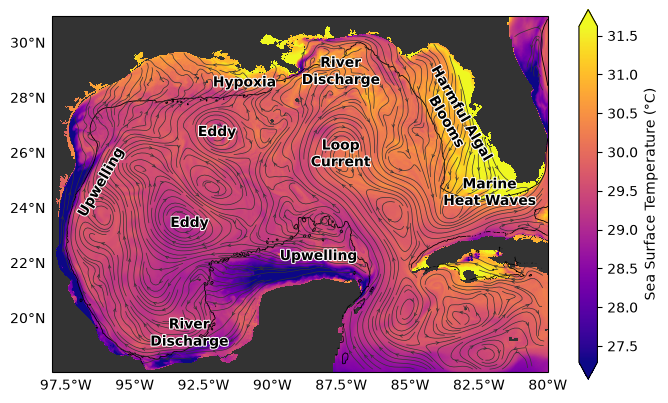

In [99]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LongitudeFormatter, LatitudeFormatter
import copy

proj = ccrs.PlateCarree()

fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={'projection': proj})

cmap = copy.copy(plt.get_cmap('plasma'))  # or 'coolwarm', 'YlGn', etc.
cmap.set_bad(color='.2')
# Render 2D grid image with colormap styling
sst.plot.imshow(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    cbar_kwargs={'label': 'Sea Surface Temperature (\u00b0C)',
        "shrink": .8,
        "pad": 0.05},
    robust=True  # Automatically scales color limits to 2nd-98th percentiles
)
ax.contour(
    z.Longitude,
    z.Latitude,
    z,
    levels=[100],
    colors="black",
    linewidths=0.6,
    transform=ccrs.PlateCarree(),
)
strm = ax.streamplot(
    u.Longitude.values, u.Latitude.values, u, v,
    transform=ccrs.PlateCarree(), # Data coordinate system
    color='.2',                  # Color lines by velocity magnitude (or a single color like 'black')
    #cmap='inferno',               # Colormap for streamlines
    density=4,                  # Density of flow lines (default is 1.0)
    linewidth=.5,                # Line thickness
    arrowsize=.5,                 # Size of direction arrows
    arrowstyle='->'
)

ax.text(
    -87.5, 26,'Loop\nCurrent',
    transform=ccrs.PlateCarree(),
    fontsize=10,fontweight="bold",
    horizontalalignment='center',   # 'left', 'center', or 'right'
    verticalalignment='center',   # 'bottom', 'center', or 'top'
    path_effects=[pe.withStroke(linewidth=1.5,foreground="white",)]
)
ax.text(
    -92, 26.8,'Eddy',
    transform=ccrs.PlateCarree(),
    fontsize=10,fontweight="bold",
    horizontalalignment='center',   # 'left', 'center', or 'right'
    verticalalignment='center',   # 'bottom', 'center', or 'top'
    path_effects=[pe.withStroke(linewidth=1.5,foreground="white",)]
)
ax.text(
    -93,23.5,'Eddy',
    transform=ccrs.PlateCarree(),
    fontsize=10,fontweight="bold",
    horizontalalignment='center',   # 'left', 'center', or 'right'
    verticalalignment='center',   # 'bottom', 'center', or 'top'
    path_effects=[pe.withStroke(linewidth=1.5,foreground="white",)]
) 
ax.text(
    -91, 28.6,'Hypoxia',
    transform=ccrs.PlateCarree(),
    fontsize=10,fontweight="bold",
    horizontalalignment='center',   # 'left', 'center', or 'right'
    verticalalignment='center',   # 'bottom', 'center', or 'top'
    path_effects=[pe.withStroke(linewidth=1.5,foreground="white",)]
)
ax.text(
    -83.4, 27.3,'Harmful Algal\nBlooms',
    transform=ccrs.PlateCarree(),
    fontsize=10,fontweight="bold",
    rotation=-60,
    horizontalalignment='center',   # 'left', 'center', or 'right'
    verticalalignment='center',   # 'bottom', 'center', or 'top'
    path_effects=[pe.withStroke(linewidth=1.5,foreground="white",)]
)
ax.text(
    -96.2, 25,'Upwelling',
    transform=ccrs.PlateCarree(),
    fontsize=10,fontweight="bold",
    rotation=60,
    horizontalalignment='center',   # 'left', 'center', or 'right'
    verticalalignment='center',   # 'bottom', 'center', or 'top'
    path_effects=[pe.withStroke(linewidth=1.5,foreground="white",)]
)
ax.text(
    -88.3, 22.3,'Upwelling',
    transform=ccrs.PlateCarree(),
    fontsize=10,fontweight="bold",
    horizontalalignment='center',   # 'left', 'center', or 'right'
    verticalalignment='center',   # 'bottom', 'center', or 'top'
    path_effects=[pe.withStroke(linewidth=1.5,foreground="white",)]
)
ax.text(
    -82.1, 24.6,'Marine\nHeat Waves',
    transform=ccrs.PlateCarree(),
    fontsize=10,fontweight="bold",
    horizontalalignment='center',   # 'left', 'center', or 'right'
    verticalalignment='center',   # 'bottom', 'center', or 'top'
    path_effects=[pe.withStroke(linewidth=1.5,foreground="white",)]
)
ax.text(
    -87.5, 29,'River\nDischarge',
    transform=ccrs.PlateCarree(),
    fontsize=10,fontweight="bold",
    horizontalalignment='center',   # 'left', 'center', or 'right'
    verticalalignment='center',   # 'bottom', 'center', or 'top'
    path_effects=[pe.withStroke(linewidth=1.5,foreground="white",)]
)
ax.text(
    -93, 19.5,'River\nDischarge',
    transform=ccrs.PlateCarree(),
    fontsize=10,fontweight="bold",
    horizontalalignment='center',   # 'left', 'center', or 'right'
    verticalalignment='center',   # 'bottom', 'center', or 'top'
    path_effects=[pe.withStroke(linewidth=1.5,foreground="white",)]
)

#ax.coastlines(resolution='50m', color='black', linewidth=1)
#ax.add_feature(
#    cfeature.LAND,
#    facecolor='.2',
#    edgecolor="none",
#    zorder=3,
#)
ax.set_aspect('equal')

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0,
    color="none"
)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 10}
gl.ylabel_style = {"size": 10}
# Remove the automatic title
ax.set_title("")

#ax.set_title("Subsetted NetCDF Domain")
plt.savefig(
    "figures/UGOS_fig1_python.png",
    dpi=300,              # Publication-grade resolution (dots per inch)
    bbox_inches="tight",  # Crops unnecessary white padding around labels/colorbar
    pad_inches=0.1,       # Adds a small, clean margin around the trimmed figure
    transparent=False,    # Keeps a solid background (or True for transparent)
    facecolor="white"     # Ensures the background canvas is crisp white
)
plt.show()

Text(-93, 19.5, 'River\nDischarge')

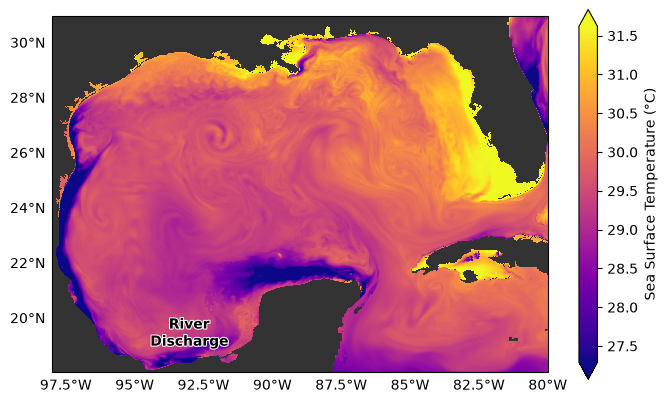

In [97]:
import matplotlib.patheffects as pe


fig, ax = plt.subplots(figsize=(8, 6), subplot_kw={'projection': proj})

plot = sst.plot.imshow(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    #add_colorbar=False,
    cbar_kwargs={'label': 'Sea Surface Temperature (\u00b0C)',
        "shrink": .8,
        "pad": 0.05},
    robust=True  # Automatically scales color limits to 2nd-98th percentiles
)
ax.set_aspect('equal')

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0,
    color="none",
)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 10}
gl.ylabel_style = {"size": 10}
# Remove the automatic title
ax.set_title("")

ax.text(
    -93, 19.5,'River\nDischarge',
    transform=ccrs.PlateCarree(),
    fontsize=10,fontweight="bold",
    horizontalalignment='center',   # 'left', 'center', or 'right'
    verticalalignment='center',   # 'bottom', 'center', or 'top'
  path_effects=[pe.withStroke(linewidth=1.5,foreground="white",)]
)

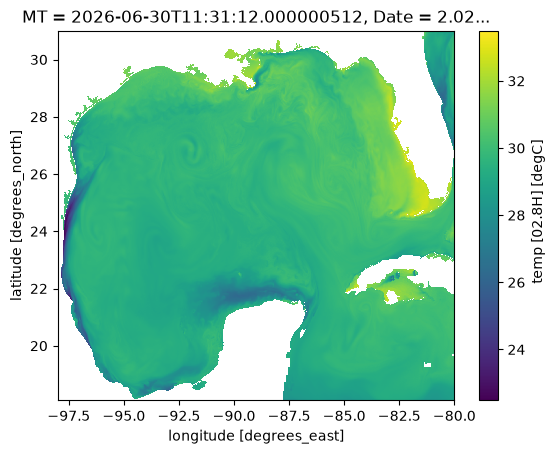

In [ ]:
import os
os.getcwd()